<h1 style="text-align: center;">Assignment 3</h1>


In [7]:
import numpy as np
from scipy.optimize import minimize

def european_call_payoff(S: float, K: float) -> float:
    return max(S - K, 0.0)

def create_spot_tree(spot: float, spot_mult_up: float, spot_mult_down: float, steps: int) -> list[list[float]]:
    previous_level = [spot]
    tree = [previous_level]
    for _ in range(steps):
        new_level = [s * spot_mult_down for s in previous_level]
        new_level += [previous_level[-1] * spot_mult_up]
        tree += [new_level]
        previous_level = new_level
    return tree

def create_discounted_price_tree(spot_tree: list[list[float]], discount_factor: float, K: float, diag: int = 0) -> list[list[float]]:
    spot_mult_up = spot_tree[1][-1]
    spot_mult_down = spot_tree[1][0]
    p_up = (1 / discount_factor - spot_mult_down) / (spot_mult_up - spot_mult_down)
    p_down = 1 - p_up
    steps = len(spot_tree) - 1
    
    continuation_value_tree = [[np.nan for _ in level] for level in spot_tree]
    
    if diag > 0:
        print("risk-neutral measure: ")
        print(('%.3f' % p_up, '%.3f' % p_down))
        delta_tree = [[np.nan for _ in level] for level in spot_tree[:-1]] 

    for i in range(len(spot_tree[-1])):
        spot = spot_tree[-1][i]
        discounted_continuation_value = (discount_factor ** steps) * european_call_payoff(spot, K)
        continuation_value_tree[-1][i] = discounted_continuation_value
        
    for step in range(steps - 1, -1, -1):
        for i in range(len(spot_tree[step])):
            continuation_value_tree[step][i] = (p_up * continuation_value_tree[step + 1][i] + 
                                                p_down * continuation_value_tree[step + 1][i + 1])
            if diag > 0:
                delta_tree[step][i] = ((continuation_value_tree[step + 1][i] - continuation_value_tree[step + 1][i + 1]) / 
                                       (spot_tree[step + 1][i] - spot_tree[step + 1][i + 1]))
                
    if diag > 0:
        print("delta: ")
        delta_tree_readable = [['%.3f' % e for e in n] for n in delta_tree]
        print(delta_tree_readable)
        
    return continuation_value_tree

def calcBalancedDownStep(spot_mult_up: float, discount_factor: float) -> float:
    return spot_mult_up - 2 * (spot_mult_up - 1 / discount_factor)

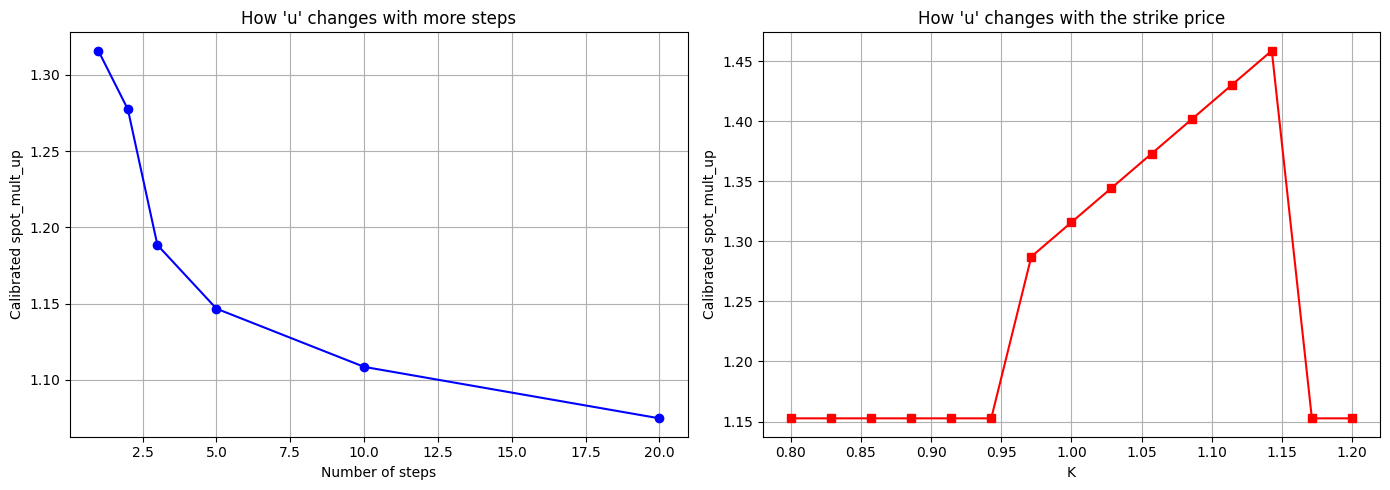

In [8]:
from scipy.optimize import minimize

def calibrate_tree(target_price: float, spot: float, K: float, steps: int, df_per_step: float) -> float:
    def objective(x):
        spot_mult_up = x[0]
        if spot_mult_up <= 1 / df_per_step:
            return 1e6
            
        spot_mult_down = calcBalancedDownStep(spot_mult_up, df_per_step)
        spot_tree = create_spot_tree(spot, spot_mult_up, spot_mult_down, steps)
        price_tree = create_discounted_price_tree(spot_tree, df_per_step, K, diag=0)
        calc_price = price_tree[0][0]
        
        return (calc_price - target_price) ** 2

    x0 = [1.0 / df_per_step + 0.1]
    bounds = [(1.0 / df_per_step + 1e-4, 3.0)]

    result = minimize(objective, x0, bounds=bounds, method='L-BFGS-B')
    
    if result.success:
        return result.x[0]
    else:
        raise ValueError("Calibration failed!")

spot_price = 1.0
annual_discount_factor = 0.95
target_option_price = 0.15
strike = 1.0

steps_list = [1, 2, 3, 5, 10, 20]
calibrated_ups_by_step = []

for s in steps_list:
    df_step = annual_discount_factor ** (1.0 / s)
    optimal_up = calibrate_tree(target_option_price, spot_price, strike, s, df_step)
    calibrated_ups_by_step.append(optimal_up)

strike_list = np.linspace(0.8, 1.2, 15)
calibrated_ups_by_strike = []
df_1step = annual_discount_factor

for K in strike_list:
    try:
        optimal_up = calibrate_tree(target_option_price, spot_price, K, 1, df_1step)
        calibrated_ups_by_strike.append(optimal_up)
    except ValueError:
        calibrated_ups_by_strike.append(np.nan)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

ax1.plot(steps_list, calibrated_ups_by_step, marker='o', color='b')
ax1.set_title("How 'u' changes with more steps")
ax1.set_xlabel("Number of steps")
ax1.set_ylabel("Calibrated spot_mult_up")
ax1.grid(True)

ax2.plot(strike_list, calibrated_ups_by_strike, marker='s', color='r')
ax2.set_title("How 'u' changes with the strike price")
ax2.set_xlabel("K")
ax2.set_ylabel("Calibrated spot_mult_up")
ax2.grid(True)

plt.tight_layout()
plt.show()